# Chapter 16

Python version of the R code for Chapter 16 of *In All Likelihood* (Pawitan, 2001).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, special

## Example 16.2 (`EX16-2.R`)

Poisson data.

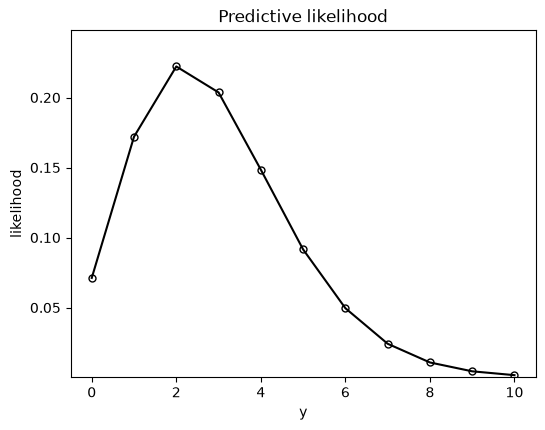

[92.9 75.7 53.5 33.1 18.2  9.1  4.1  1.7  0.6  0.2  0. ]


In [2]:
x = np.array([3, 2, 5, 0, 4])
n = len(x)
mu = np.linspace(.1, 10, 100)
ll = -n * mu + x.sum() * np.log(mu)
like = np.exp(ll - ll.max())

# Prediction
y = np.arange(1, 11)
ly = np.log(y)
y = np.concatenate([[0], y])
sumly = np.concatenate([[0], np.cumsum(ly)])  # log y! (with 0! = 1 for y=0)
thetay = (y + x.sum()) / (n + 1)
ll = -(n + 1) * thetay + (y + x.sum()) * np.log(thetay) - sumly
ll = np.exp(ll - ll.max())
like = ll / ll.sum()

# plug-in
gy = stats.poisson.pmf(y, x.mean())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(y, like, "k-o", mfc="none", ms=5)
ax.set_ylim(min(like.min(), gy.min()), max(like.max(), gy.max()) * 1.04)
# ax.plot(y, gy, "k:", lw=1.5)
ax.set_xlabel("y")
ax.set_ylabel("likelihood")
ax.set_title("Predictive likelihood")
plt.show()

print(np.round(100 - np.cumsum(like) * 100, 1))

## Figure 16.1 (`FIG16-1.R`)

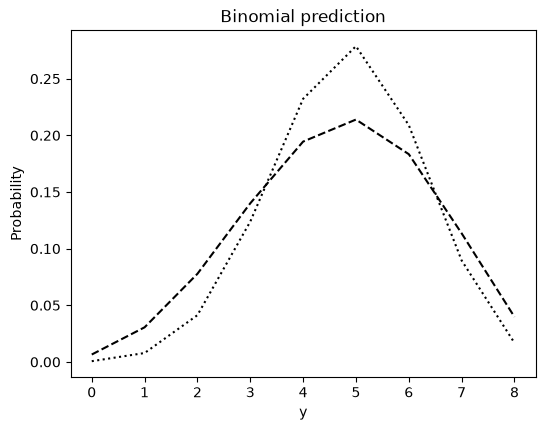

In [3]:
N = 10
a = int(np.floor(.6 * N))
b = N - a
n = 8
x = np.arange(0, n + 1)
y = n - x
gx = stats.binom.pmf(x, n, a / N)  # plug-in solution

# Bayesian solution:
lg = special.gammaln
bx = (lg(n + 1) + lg(a + x + 1) + lg(b + y + 1) + lg(N + 1)
      - lg(a + 1) - lg(b + 1) - lg(x + 1) - lg(y + 1) - lg(N + n + 1))
bx = np.exp(bx - bx.max())
bx = bx / bx.sum()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(x, gx, "k:", lw=1.5)
ax.plot(x, bx, "k--")
ax.set_xlabel("y")
ax.set_ylabel("Probability")
ax.set_title("Binomial prediction")
plt.show()

## Figure 16.2 (`FIG16-2.R`)

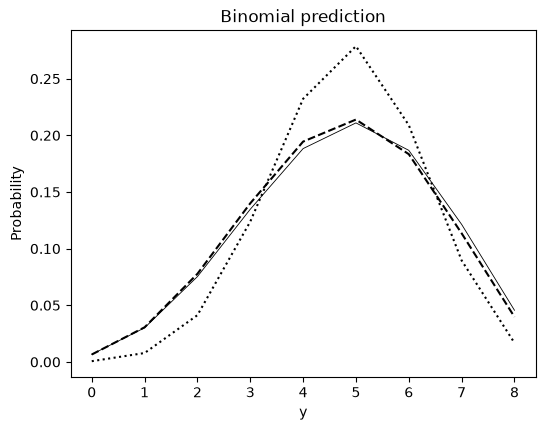

In [4]:
N = 10
a = int(np.floor(.6 * N))
b = N - a
n = 8
x = np.arange(0, n + 1)
y = n - x

# likelihood solution
with np.errstate(divide="ignore", invalid="ignore"):
    fx = (lg(n + 1) - lg(x + 1) - lg(y + 1)
          + special.xlogy(a + x, a + x) + special.xlogy(b + y, b + y) - (N + n) * np.log(N + n))
fx = np.exp(fx - fx.max())
fx = fx / fx.sum()

# plug-in solution
gx = stats.binom.pmf(x, n, a / N)

# Bayesian solution:
bx = (lg(n + 1) + lg(a + x + 1) + lg(b + y + 1) + lg(N + 1)
      - lg(a + 1) - lg(b + 1) - lg(x + 1) - lg(y + 1) - lg(N + n + 1))
bx = np.exp(bx - bx.max())
bx = bx / bx.sum()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(x, fx, "k-", lw=0.6)
ax.plot(x, gx, "k:", lw=1.5)
ax.plot(x, bx, "k--")
ax.set_xlabel("y")
ax.set_ylabel("Probability")
ax.set_title("Binomial prediction")
plt.show()